# Compass EDA: Atlanta Coverage and One Intersection

First locate areas with many Compass observations, then examine **Northside Drive NW at 10th Street NW** in detail. All tables and maps remain in this notebook; no result files are exported.

Counts describe observed Compass trips, not all road traffic. Run the code cells in order. `MAX_TRIPS=None` reads all Atlanta trip files; setting a number previews the first rows only, not a representative sample.

In [1]:
from pathlib import Path
from collections import defaultdict, Counter
from datetime import date
from time import perf_counter
import csv, gzip, json, re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.colors import LogNorm, Normalize, to_hex
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'data/raw/Atlanta_compass_aug2026').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Run this notebook from the repository root or notebooks/.')
DATA_DIR = ROOT / 'data/raw/Atlanta_compass_aug2026'
MANIFEST = json.loads((ROOT / 'data/raw/manifest.json').read_text())
TRIP_FILES = sorted(DATA_DIR.glob('trips-*.csv.gz'))
GRID_SIZE_M = 500       # Rerun aggregation after changing this; distances use a local approximation.
MAX_TRIPS = None        # None = all trips; 2000 previews the first 2,000 rows, not a representative sample.
assert GRID_SIZE_M > 0 and (MAX_TRIPS is None or MAX_TRIPS > 0)
assert len(TRIP_FILES) == next(o['files'] for o in MANIFEST['outputs'] if o['report'] == 'trips')
area_wkts = MANIFEST['request']['area_wkt']
assert len(area_wkts) == 1 and area_wkts[0].startswith('POLYGON')
AREA_RING = np.array([float(x) for x in re.findall(r'-?\d+(?:\.\d+)?', area_wkts[0])]).reshape(-1, 2)
assert np.allclose(AREA_RING[0], AREA_RING[-1])
assert -85 < AREA_RING[:, 0].mean() < -84 and 33 < AREA_RING[:, 1].mean() < 34

# Local equirectangular projection for this small Atlanta area, not surveying.
# Do not interpret Web Mercator map meters as ground distances.
EARTH_RADIUS_M = 6371008.8
LON0, LAT0 = AREA_RING[:-1].mean(axis=0)
COS_LAT0 = np.cos(np.radians(LAT0))
def project(lonlat):
    p = np.asarray(lonlat, dtype=float)
    return np.column_stack((EARTH_RADIUS_M * COS_LAT0 * np.radians(p[:, 0] - LON0),
                            EARTH_RADIUS_M * np.radians(p[:, 1] - LAT0)))
def unproject(xy):
    p = np.asarray(xy, dtype=float)
    return np.column_stack((LON0 + np.degrees(p[:, 0] / (EARTH_RADIUS_M * COS_LAT0)),
                            LAT0 + np.degrees(p[:, 1] / EARTH_RADIUS_M)))
AREA_XY = project(AREA_RING)
GRID_ORIGIN = np.floor(AREA_XY.min(axis=0) / GRID_SIZE_M) * GRID_SIZE_M
NX, NY = np.ceil((AREA_XY.max(axis=0) - GRID_ORIGIN) / GRID_SIZE_M).astype(int)

def inside_area(lonlat):
    p = np.asarray(lonlat, dtype=float)
    x, y = p[:, 0], p[:, 1]
    inside = np.zeros(len(p), dtype=bool)
    boundary = np.zeros(len(p), dtype=bool)
    for a, b in zip(AREA_RING[:-1], AREA_RING[1:]):
        dx, dy = b - a
        cross = (x - a[0]) * dy - (y - a[1]) * dx
        boundary |= ((np.abs(cross) <= 1e-12) & (x >= min(a[0], b[0]) - 1e-12)
                     & (x <= max(a[0], b[0]) + 1e-12) & (y >= min(a[1], b[1]) - 1e-12)
                     & (y <= max(a[1], b[1]) + 1e-12))
        if dy != 0:
            inside ^= ((a[1] > y) != (b[1] > y)) & (x < a[0] + dx * (y - a[1]) / dy)
    return inside | boundary

def grid_ids(lonlat):
    ij = np.floor((project(lonlat) - GRID_ORIGIN) / GRID_SIZE_M).astype(np.int64)
    assert np.all((ij[:, 0] >= 0) & (ij[:, 0] < NX) & (ij[:, 1] >= 0) & (ij[:, 1] < NY))
    return ij[:, 1] * NX + ij[:, 0]

def cell_polygon(cell_id):
    ix, iy = int(cell_id) % NX, int(cell_id) // NX
    lower = GRID_ORIGIN + GRID_SIZE_M * np.array([ix, iy])
    return unproject(lower + GRID_SIZE_M * np.array([[0, 0], [1, 0], [1, 1], [0, 1]]))

csv.field_size_limit(sys.maxsize)
print(f'Atlanta trip files: {len(TRIP_FILES)} | compressed: {sum(f.stat().st_size for f in TRIP_FILES)/1e9:.2f} GB')
print(f'Grid: ~{GRID_SIZE_M:,} m | {NX} × {NY} cells')
print('Scope:', 'ALL TRIPS' if MAX_TRIPS is None else f'FIRST {MAX_TRIPS:,} ROWS ONLY')


# Center between the two Northside carriageways at 10th Street.
# OSM nodes 69594786 and 5443534937; road geometry checked on 2026-11-02.
SITE_NAME = 'Northside Drive NW at 10th Street NW'
SITE_LON, SITE_LAT = -84.4074832, 33.7815554
SITE_CENTER_XY = project([[SITE_LON, SITE_LAT]])[0]
APPROACH_ORDER = ['N', 'E', 'S', 'W']
APPROACH_LABELS = {'N': 'From north (southbound)', 'E': 'From east (westbound)',
                   'S': 'From south (northbound)', 'W': 'From west (eastbound)'}
ARM_UNIT = {'N': np.array([0., 1.]), 'E': np.array([1., 0.]),
            'S': np.array([0., -1.]), 'W': np.array([-1., 0.])}
GATE_DISTANCE_M = 90.0
CORRIDOR_HALF_WIDTH_M = 25.0
ARM_EXTENT_M = 140.0
CORE_RADIUS_M = 35.0
MAX_GAP_S = 10.0
MAX_STEP_M = 100.0
MAX_VISIT_S = 900.0
assert 0 < CORE_RADIUS_M < GATE_DISTANCE_M < ARM_EXTENT_M
print(f'Site: {SITE_NAME} | center: {SITE_LAT:.7f}, {SITE_LON:.7f}')


Atlanta trip files: 14 | compressed: 1.54 GB
Grid: ~500 m | 24 × 22 cells
Scope: ALL TRIPS
Site: Northside Drive NW at 10th Street NW | center: 33.7815554, -84.4074832


## Read and Count the Trips Once

Each compressed trip row contains a timestamped path. Read rows one at a time and reuse them for both analyses. Treat `VehicleID + TripID + StartTimestamp_UTC` as the trip key and skip duplicate keys.

For the Atlanta grid, count each vehicle and trip once per cell, regardless of how many points or revisits it has. Count dates from the local observation times. Missing coordinates are excluded without shifting the remaining timestamps. Do not interpolate across missing positions or fill cells between observed points.

The intersection analysis uses the entry/exit rules explained below. Its compact event table stays in memory. A kernel restart requires rerunning this cell to recreate both datasets.

In [2]:

class IntersectionScanner:
    def __init__(self):
        self.records = []
        self.stats = Counter()
        self.examples = defaultdict(list)
        self.example_seen = Counter()
        self.rng = np.random.default_rng(42)

    def add_trip(self, trip_key, coords, timestamp_path):
        xy = project(coords) - SITE_CENTER_XY
        finite = np.isfinite(xy).all(axis=1)
        nearby = finite & (np.abs(xy).max(axis=1) <= ARM_EXTENT_M + CORRIDOR_HALF_WIDTH_M)
        if not nearby.any():
            return
        self.stats['nearby_trip_rows'] += 1
        times = np.asarray(timestamp_path.split(','), dtype='datetime64[ms]')
        if len(times) != len(xy):
            raise ValueError('Site coordinates and timestamps are not aligned.')
        valid = finite & ~np.isnat(times)
        dt = np.diff(times).astype('timedelta64[ms]').astype(float) / 1000
        step = np.linalg.norm(np.diff(xy, axis=0), axis=1)
        adjacent_valid = valid[:-1] & valid[1:]
        good = adjacent_valid & (dt > 0) & (dt <= MAX_GAP_S) & (step <= MAX_STEP_M)
        near_segment = nearby[:-1] | nearby[1:]
        self.stats['nearby_adjacent_pairs'] += int((near_segment & adjacent_valid).sum())
        self.stats['nearby_rejected_pairs'] += int((near_segment & ~good).sum())
        # Breaking at an invalid position or gap prevents stitching separate path fragments.
        chunk = np.r_[0, np.cumsum(~good)]
        radius = np.linalg.norm(xy, axis=1)
        core_idx = np.flatnonzero(valid & (radius <= CORE_RADIUS_M))
        entries, exits = [], []
        for arm in APPROACH_ORDER:
            unit = ARM_UNIT[arm]
            along = xy @ unit
            lateral = xy @ np.array([-unit[1], unit[0]])
            crossing = good & (((along[:-1] >= GATE_DISTANCE_M) & (along[1:] < GATE_DISTANCE_M))
                               | ((along[:-1] < GATE_DISTANCE_M) & (along[1:] >= GATE_DISTANCE_M)))
            crossing &= (np.abs(np.diff(along)) >= 0.5)
            for i in np.flatnonzero(crossing):
                fraction = (GATE_DISTANCE_M - along[i]) / (along[i+1] - along[i])
                cross_lateral = lateral[i] + fraction * (lateral[i+1] - lateral[i])
                # Both endpoints must still lie on this road corridor; no diagonal shortcuts.
                if (abs(cross_lateral) > CORRIDOR_HALF_WIDTH_M
                    or max(abs(lateral[i]), abs(lateral[i+1])) > CORRIDOR_HALF_WIDTH_M
                    or min(along[i], along[i+1]) < 0):
                    continue
                t = times[i] + np.timedelta64(int(round(fraction * dt[i] * 1000)), 'ms')
                event = {'arm': arm, 'i': int(i), 'time': t, 'chunk': int(chunk[i])}
                (entries if along[i+1] < along[i] else exits).append(event)
        entries.sort(key=lambda e: e['time'])
        exits.sort(key=lambda e: e['time'])
        self.stats['inbound_gate_events'] += len(entries)
        self.stats['outbound_gate_events'] += len(exits)
        if not entries:
            self.stats['nearby_trips_without_entry'] += 1
            return

        # Use the first inward crossing per approach within a trip, not every GPS recrossing.
        first_entry = {}
        for entry in entries:
            first_entry.setdefault(entry['arm'], entry)
        for arm, entry in first_entry.items():
            linked_exit = None
            for leave in exits:
                duration = (leave['time'] - entry['time']) / np.timedelta64(1, 's')
                if duration <= 0:
                    continue
                if duration > MAX_VISIT_S:
                    break
                if leave['chunk'] != entry['chunk']:
                    continue
                core_between = core_idx[(core_idx > entry['i']) & (core_idx <= leave['i'])]
                if not len(core_between):
                    continue
                # An additional entry from another arm indicates a separate/ambiguous visit.
                another_entry = any(e['arm'] != arm and entry['time'] < e['time'] < leave['time']
                                    for e in entries)
                if another_entry:
                    continue
                linked_exit = leave
                break
            connected = linked_exit is not None
            status = 'Connected entry-core-exit' if connected else 'Entry observed; exit not linked'
            exit_arm = linked_exit['arm'] if connected else None
            rec = {'trip_key': trip_key, 'approach': arm, 'entry_time': entry['time'],
                   'connected': connected, 'exit_arm': exit_arm,
                   'exit_time': linked_exit['time'] if connected else np.datetime64('NaT'),
                   'visit_seconds': float((linked_exit['time'] - entry['time']) / np.timedelta64(1, 's')) if connected else np.nan,
                   'u_turn': connected and exit_arm == arm}
            self.records.append(rec)
            self.stats['observed_trip_approach_pairs'] += 1
            self.stats['connected_trip_approach_pairs'] += int(connected)
            if connected:
                idx = np.arange(entry['i'], linked_exit['i'] + 2)
            else:
                idx = np.flatnonzero((chunk == entry['chunk']) & nearby)
            # Keep only a small reproducible reservoir for visual checks; never join broken runs.
            idx = idx[nearby[idx] & valid[idx]]
            breaks = np.r_[True, np.diff(idx) > 1]
            groups = np.cumsum(breaks)
            segments = [xy[idx[groups == g]][::max(1, int((groups == g).sum()) // 100)]
                        for g in np.unique(groups) if (groups == g).sum() >= 2]
            example = {'segments': segments, 'approach': arm, 'status': status}
            group = (arm, connected)
            self.example_seen[group] += 1
            reservoir = self.examples[group]
            if len(reservoir) < 6:
                reservoir.append(example)
            else:
                j = int(self.rng.integers(self.example_seen[group]))
                if j < 6:
                    reservoir[j] = example


def aggregate_coverage(files, max_trips=None, site_scanner=None):
    vehicle_codes = {}
    cell_vehicles = defaultdict(set)
    cell_trips, cell_points = Counter(), Counter()
    cell_dates = defaultdict(set)
    seen_trips, observed_dates = set(), set()
    stats = Counter()
    started = perf_counter()
    required = {'VehicleID', 'TripID', 'StartTimestamp_UTC', 'StartTimestamp_Local',
                'EndTimestamp_Local', 'SnappedPath', 'TimestampPath'}
    for file_no, path in enumerate(files, 1):
        with gzip.open(path, 'rt', newline='') as handle:
            reader = csv.DictReader(handle)
            if not required.issubset(reader.fieldnames):
                raise ValueError(f'Missing columns in {path.name}')
            for row in reader:
                if max_trips is not None and stats['rows_read'] >= max_trips:
                    break
                stats['rows_read'] += 1
                vehicle = row['VehicleID']
                key = (vehicle, row['TripID'], row['StartTimestamp_UTC'])
                if not all(key):
                    raise ValueError(f'Missing identifier: row {stats["rows_read"]}')
                if key in seen_trips:
                    stats['duplicate_trip_rows'] += 1
                    continue
                seen_trips.add(key)
                text = row['SnappedPath'].strip()
                if not text:
                    stats['empty_paths'] += 1
                    continue
                point_count = text.count(',') + 1
                # Missing coordinate entries use a single 'null' token; preserve point alignment.
                clean_text = re.sub(r'(^|,)\s*null\s*(?=,|$)', r'\1nan nan', text, flags=re.IGNORECASE)
                flat = np.fromstring(clean_text.replace(',', ' '), sep=' ')
                if flat.size != 2 * point_count:
                    raise ValueError(f'Malformed coordinates: row {stats["rows_read"]}')
                if row['TimestampPath'].count(',') + 1 != point_count:
                    raise ValueError(f'Timestamp/path length mismatch: row {stats["rows_read"]}')
                coords = flat.reshape(-1, 2)
                stats['positions_read'] += len(coords)
                if site_scanner is not None:
                    site_scanner.add_trip(key, coords, row['TimestampPath'])
                finite = np.isfinite(coords).all(axis=1)
                stats['invalid_positions'] += int((~finite).sum())
                keep = finite & inside_area(coords)
                stats['outside_area_positions'] += int((finite & ~keep).sum())
                coords = coords[keep]
                if not len(coords):
                    stats['trips_without_in_area_points'] += 1
                    continue
                ids = grid_ids(coords)
                unique_ids, counts = np.unique(ids, return_counts=True)
                vehicle_code = vehicle_codes.setdefault(vehicle, len(vehicle_codes))
                first_day, last_day = row['StartTimestamp_Local'][:10], row['EndTimestamp_Local'][:10]
                date.fromisoformat(first_day)
                date.fromisoformat(last_day)
                if first_day == last_day:
                    for cell in unique_ids:
                        cell_dates[int(cell)].add(first_day)
                    observed_dates.add(first_day)
                else:
                    days = np.asarray([t.strip()[:10] for t in row['TimestampPath'].split(',')])[keep]
                    for day in np.unique(days):
                        date.fromisoformat(str(day))
                        observed_dates.add(str(day))
                        for cell in np.unique(ids[days == day]):
                            cell_dates[int(cell)].add(str(day))
                for cell, count in zip(unique_ids, counts):
                    cell = int(cell)
                    cell_vehicles[cell].add(vehicle_code)
                    cell_trips[cell] += 1
                    cell_points[cell] += int(count)
                stats['trips_used'] += 1
                stats['positions_used'] += len(coords)
        elapsed = perf_counter() - started
        print(f'[{file_no:02d}/{len(files)}] {path.name} | rows {stats["rows_read"]:,} | '
              f'used {stats["trips_used"]:,} | cells {len(cell_trips):,} | {elapsed/60:.1f} min', flush=True)
        if max_trips is not None and stats['rows_read'] >= max_trips:
            break
    records = []
    for cell in sorted(cell_trips):
        lon, lat = cell_polygon(cell).mean(axis=0)
        records.append({'cell_id': cell, 'center_lon': lon, 'center_lat': lat,
                        'unique_vehicles': len(cell_vehicles[cell]), 'unique_trips': cell_trips[cell],
                        'observed_days': len(cell_dates[cell]), 'point_count': cell_points[cell]})
    coverage = pd.DataFrame(records)
    if coverage.empty:
        raise ValueError('No observed positions inside the Atlanta polygon.')
    assert (coverage['unique_trips'] >= coverage['unique_vehicles']).all()
    assert coverage['observed_days'].between(1, len(observed_dates)).all()
    assert int(coverage['point_count'].sum()) == stats['positions_used']
    stats.update(unique_vehicles=len(vehicle_codes), unique_trip_keys=len(seen_trips),
                 observed_days=len(observed_dates), occupied_cells=len(coverage))
    stats['elapsed_seconds'] = round(perf_counter() - started, 1)
    return coverage, dict(stats), sorted(observed_dates)

site_scanner = IntersectionScanner()
coverage, coverage_stats, coverage_dates = aggregate_coverage(TRIP_FILES, MAX_TRIPS, site_scanner)
passages = pd.DataFrame(site_scanner.records, columns=[
    'trip_key', 'approach', 'entry_time', 'connected', 'exit_arm', 'exit_time', 'visit_seconds', 'u_turn'])
if not passages.empty:
    passages['entry_time'] = pd.to_datetime(passages['entry_time'])
    passages['exit_time'] = pd.to_datetime(passages['exit_time'])
    passages['local_date'] = passages['entry_time'].dt.normalize()
    passages['hour'] = passages['entry_time'].dt.hour
    passages['day_type'] = np.where(passages['entry_time'].dt.day_of_week < 5, 'Weekday', 'Weekend')
site_stats = dict(site_scanner.stats)
print('Complete. No external output files were written.')


[01/14] trips-d3e2550d3e6b-000000000000.csv.gz | rows 18,732 | used 18,731 | cells 481 | 0.2 min


[02/14] trips-d3e2550d3e6b-000000000001.csv.gz | rows 37,077 | used 37,071 | cells 485 | 0.4 min


[03/14] trips-d3e2550d3e6b-000000000002.csv.gz | rows 55,577 | used 55,567 | cells 489 | 0.6 min


[04/14] trips-d3e2550d3e6b-000000000003.csv.gz | rows 74,140 | used 74,128 | cells 489 | 0.8 min


[05/14] trips-d3e2550d3e6b-000000000004.csv.gz | rows 92,534 | used 92,518 | cells 489 | 1.1 min


[06/14] trips-d3e2550d3e6b-000000000005.csv.gz | rows 111,224 | used 111,206 | cells 489 | 1.3 min


... (5 outputs left out)

[12/14] trips-d3e2550d3e6b-000000000011.csv.gz | rows 222,228 | used 222,191 | cells 489 | 2.5 min


[13/14] trips-d3e2550d3e6b-000000000012.csv.gz | rows 240,704 | used 240,666 | cells 489 | 2.7 min


[14/14] trips-d3e2550d3e6b-000000000013.csv.gz | rows 259,341 | used 259,298 | cells 489 | 2.9 min


Complete. No external output files were written.


## Atlanta Coverage Summary

One vehicle or trip can occur in several cells; cell counts must not be summed to obtain dataset-wide totals. Uncolored cells have no observations in this extract, not necessarily zero traffic. Observed dates do not imply coverage throughout each day.

In [3]:
if 'coverage_stats' not in globals():
    raise RuntimeError('Run the setup and streaming aggregation cells above first.')

summary_labels = {
    'rows_read': 'Trip rows read', 'duplicate_trip_rows': 'Duplicate trip rows skipped',
    'trips_used': 'Trips with in-area positions', 'unique_vehicles': 'Unique observed vehicles',
    'positions_read': 'Positions read', 'positions_used': 'Positions inside extraction polygon',
    'outside_area_positions': 'Outside-polygon positions excluded', 'invalid_positions': 'Invalid positions',
    'empty_paths': 'Empty paths', 'trips_without_in_area_points': 'Trips without in-area points',
    'observed_days': 'Observed local dates', 'occupied_cells': 'Occupied grid cells',
    'elapsed_seconds': 'Elapsed seconds'}
display(pd.DataFrame([{'Measure': label, 'Value': coverage_stats.get(key, 0)}
                      for key, label in summary_labels.items()]))
print(f'Local dates: {coverage_dates[0]} to {coverage_dates[-1]}')
scope_label = 'All Atlanta trip files' if MAX_TRIPS is None else f'Preview: first {MAX_TRIPS:,} rows'
print('Scope:', scope_label)
if MAX_TRIPS is None:
    expected = next(o['rows'] for o in MANIFEST['outputs'] if o['report'] == 'trips')
    assert coverage_stats['rows_read'] == expected, 'Trip count differs from manifest.'
    print('Trip row count matches manifest.')
columns = ['cell_id', 'center_lat', 'center_lon', 'unique_vehicles', 'unique_trips', 'observed_days']
display(coverage.nlargest(10, 'unique_vehicles')[columns].reset_index(drop=True).round(6))


,Measure,Value
0,Trip rows read,259341.0
1,Duplicate trip rows skipped,0.0
2,Trips with in-area positions,259298.0
3,Unique observed vehicles,237176.0
4,Positions read,53949739.0
5,Positions inside extraction polygon,53320176.0
6,Outside-polygon positions excluded,18389.0
7,Invalid positions,611174.0
8,Empty paths,0.0
9,Trips without in-area points,43.0


Local dates: 2026-08-01 to 2026-08-31
Scope: All Atlanta trip files
Trip row count matches manifest.


,cell_id,center_lat,center_lon,unique_vehicles,unique_trips,observed_days
0,206,33.745632,-84.391863,86467,90463,31
1,207,33.745632,-84.386455,83606,87499,31
2,470,33.795095,-84.391863,80006,83627,31
3,446,33.790598,-84.391863,76961,80457,31
4,422,33.786102,-84.391863,75035,78401,31
5,398,33.781605,-84.391863,73806,77277,31
6,350,33.772612,-84.391863,71218,74610,31
7,374,33.777108,-84.391863,69389,72651,31
8,326,33.768115,-84.391863,69114,71842,31
9,327,33.768115,-84.386455,68907,71965,31


## Atlanta Grid Maps

Vehicle/trip counts use logarithmic colors; observed dates use a linear scale. Each panel has its own color scale. The outline marks the extraction area. Boundary cells may extend beyond it, but their counts use only in-area observations.

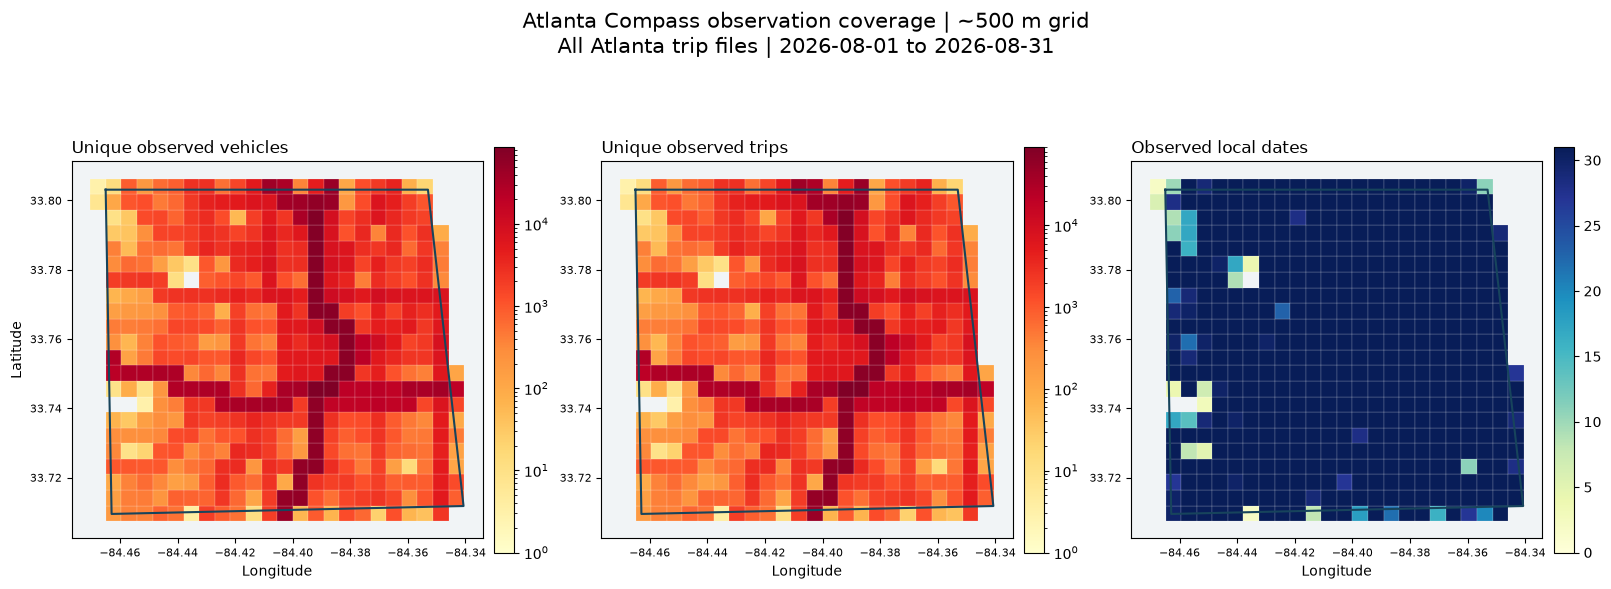

In [4]:
if 'coverage' not in globals():
    raise RuntimeError('Run the setup and streaming aggregation cells above first.')

metrics = [('unique_vehicles', 'Unique observed vehicles', 'YlOrRd'),
           ('unique_trips', 'Unique observed trips', 'YlOrRd'),
           ('observed_days', 'Observed local dates', 'YlGnBu')]
polygons = [cell_polygon(c) for c in coverage['cell_id']]
fig, axes = plt.subplots(1, 3, figsize=(16, 6.3), constrained_layout=True)
for ax, (key, title, cmap) in zip(axes, metrics):
    values = coverage[key].to_numpy()
    norm = (Normalize(vmin=0, vmax=max(1, int(values.max()))) if key == 'observed_days'
            else LogNorm(vmin=1, vmax=max(2, int(values.max()))))
    mesh = PolyCollection(polygons, array=values.astype(float), cmap=cmap, norm=norm,
                          edgecolors='white', linewidths=.12)
    ax.add_collection(mesh)
    ax.plot(AREA_RING[:, 0], AREA_RING[:, 1], color='#17445c', linewidth=1.5)
    ax.autoscale_view()
    ax.set_aspect(1 / COS_LAT0)
    ax.set_title(title, fontsize=12, loc='left')
    ax.set_xlabel('Longitude')
    ax.ticklabel_format(useOffset=False)
    ax.tick_params(labelsize=8)
    ax.set_facecolor('#f1f4f6')
    fig.colorbar(mesh, ax=ax, shrink=.72, pad=.02)
axes[0].set_ylabel('Latitude')
fig.suptitle(f'Atlanta Compass observation coverage | ~{GRID_SIZE_M:,} m grid\n'
             f'{scope_label} | {coverage_dates[0]} to {coverage_dates[-1]}', fontsize=15)
plt.show()


## Interactive Coverage Map

Switch the metric with the selector above the map. Hover over a cell for counts and coordinates; the dark marker locates the selected intersection. The map uses VS Code/JupyterLab's native Plotly output, not an HTML iframe. Background road tiles require internet access. If only a text message appears, choose the Plotly output renderer in the notebook viewer. No HTML file is created.

In [5]:
if 'coverage' not in globals():
    raise RuntimeError('Run the setup and streaming aggregation cells above first.')

# Use VS Code's installed Plotly renderer rather than an HTML iframe.
# This is the standard Plotly notebook MIME format; no Python Plotly package is required.
map_features = []
for row in coverage.itertuples(index=False):
    polygon = cell_polygon(row.cell_id).tolist()
    polygon.append(polygon[0])
    map_features.append({'type': 'Feature', 'id': str(row.cell_id),
                         'geometry': {'type': 'Polygon', 'coordinates': [polygon]}})
map_geojson = {'type': 'FeatureCollection', 'features': map_features}
map_metrics = [('unique_vehicles', 'Unique observed vehicles', 'YlOrRd'),
               ('unique_trips', 'Unique observed trips', 'YlOrRd'),
               ('observed_days', 'Observed local dates', 'YlGnBu')]

def map_metric_settings(key, title, cmap):
    values = coverage[key].to_numpy(dtype=float)
    maximum = float(values.max())
    if key == 'observed_days':
        z = values.tolist()
        tickvals = sorted(set([0, 7, 14, 21, 28, int(maximum)]))
        tickvals = [v for v in tickvals if v <= maximum]
        label = title
        zmax = max(1, maximum)
    else:
        z = np.log10(values).tolist()
        zmax = np.log10(max(2, maximum))
        tickvals = list(np.arange(0, np.floor(zmax) + 1, dtype=float))
        if zmax > tickvals[-1] + 0.15:
            tickvals.append(float(zmax))
        label = title + '<br>(log color scale)'
    ticktext = ([str(int(v)) for v in tickvals] if key == 'observed_days'
                else [f'{10**v:,.0f}' for v in tickvals])
    colors = [[i/63, to_hex(plt.get_cmap(cmap)(.12 + .85*i/63))] for i in range(64)]
    return {'z': z, 'zmax': float(zmax), 'colorscale': colors,
            'colorbar': {'title': {'text': label}, 'tickvals': tickvals,
                         'ticktext': ticktext, 'thickness': 16, 'len': .75}}

map_settings = [map_metric_settings(*spec) for spec in map_metrics]
initial = map_settings[0]
customdata = coverage[['cell_id', 'unique_vehicles', 'unique_trips', 'observed_days',
                       'center_lat', 'center_lon']].to_numpy().tolist()
map_traces = [
    {'type': 'choroplethmap', 'geojson': map_geojson,
     'locations': coverage['cell_id'].astype(str).tolist(), 'z': initial['z'],
     'zmin': 0, 'zmax': initial['zmax'], 'zauto': False,
     'colorscale': initial['colorscale'], 'colorbar': initial['colorbar'],
     'marker': {'opacity': .62, 'line': {'color': '#ffffff', 'width': .4}},
     'customdata': customdata, 'name': 'Grid coverage',
     'hovertemplate': ('Cell %{customdata[0]:.0f}<br>Vehicles: %{customdata[1]:,.0f}'
                       '<br>Trips: %{customdata[2]:,.0f}<br>Observed dates: %{customdata[3]:.0f}'
                       '<br>Center: %{customdata[4]:.6f}, %{customdata[5]:.6f}<extra></extra>')},
    {'type': 'scattermap', 'lat': AREA_RING[:,1].tolist(), 'lon': AREA_RING[:,0].tolist(),
     'mode': 'lines', 'line': {'color': '#153f5d', 'width': 2},
     'hoverinfo': 'skip', 'showlegend': False},
    {'type': 'scattermap', 'lat': [SITE_LAT], 'lon': [SITE_LON], 'mode': 'markers',
     'marker': {'size': 14, 'color': '#1c4761'}, 'text': [SITE_NAME],
     'hovertemplate': '%{text}<extra>Selected intersection</extra>', 'showlegend': False}
]
buttons = []
for (_, label, _), settings in zip(map_metrics, map_settings):
    buttons.append({'label': label, 'method': 'update',
                    'args': [{'z': [settings['z']], 'zmax': [settings['zmax']],
                              'colorscale': [settings['colorscale']],
                              'colorbar': [settings['colorbar']]}, {}, [0]]})
map_figure = {
    'data': map_traces,
    'layout': {
        'height': 700, 'margin': {'l': 10, 'r': 10, 't': 140, 'b': 25},
        'font': {'family': 'Arial, sans-serif', 'size': 12, 'color': '#173548'},
        'title': {'text': (f'Atlanta Compass observation coverage — ~{GRID_SIZE_M:,} m grid'
                           f'<br><sup>{scope_label} | {coverage_dates[0]} to {coverage_dates[-1]}</sup>'),
                  'x': .02, 'xanchor': 'left', 'font': {'size': 18}},
        'map': {'style': 'open-street-map', 'center': {'lat': float(LAT0), 'lon': float(LON0)}, 'zoom': 11.6},
        'updatemenus': [{'buttons': buttons, 'direction': 'down', 'x': .01, 'y': 1.02,
                         'xanchor': 'left', 'yanchor': 'bottom', 'showactive': True}],
        'uirevision': 'atlanta-coverage'
    },
    'config': {'responsive': True, 'scrollZoom': True, 'displaylogo': False,
               'modeBarButtonsToRemove': ['toImage']}
}
# Standard JSON types make the saved MIME output portable between supported notebook viewers.
map_figure = json.loads(json.dumps(map_figure, allow_nan=False))
display({'application/vnd.plotly.v1+json': map_figure,
         'text/plain': 'Interactive road map: use the Plotly renderer in VS Code or JupyterLab.'}, raw=True)


Interactive road map: use the Plotly renderer in VS Code or JupyterLab.

## Northside Drive at 10th Street: What Is Counted?

**Approach means the side the vehicle comes from.** N is a vehicle arriving from the north (travelling south); E is from the east (travelling west). S and W follow the same convention. Northside has separate carriageways, but both are treated as one north-south road for this screening EDA.

The diagram below shows four road corridors, **25 m on either side of each center axis**, and counting gates **90 m from the intersection center**. A trip is observed on an approach when two consecutive positions show it crossing that gate toward the intersection. Interpolate the gate time between those two accepted observations. Repeated crossings within the same trip/approach count once. A trip seen on two approaches may count in both, so approach totals are trip-approach pairs, not necessarily distinct trips.

A trajectory is **connected** only if an observed inbound gate crossing is followed by a position within **35 m of the center**, then an outbound gate crossing within **15 minutes**. All intervening positions must be present, time must increase, each gap must be **10 seconds or less**, and each step must be **100 m or less**. A broken path is not stitched into a complete crossing. These thresholds are editable screening choices, not verified signal timing or ground-truth vehicle movements.

The 140 m drawing extent stays short of the next Northside cross street to the north. Corridors are geometric approximations, not lane-level map matching; inspect the sample paths before interpreting the counts. An unlinked exit means insufficient evidence under these rules, not that the vehicle failed to cross.

Geometry reference: [OpenStreetMap](https://www.openstreetmap.org/#map=19/33.7815554/-84.4074832), checked 2026-11-02. The center is midway between OSM nodes 69594786 and 5443534937; present-day road geometry is a starting reference for the August 2026 observations.

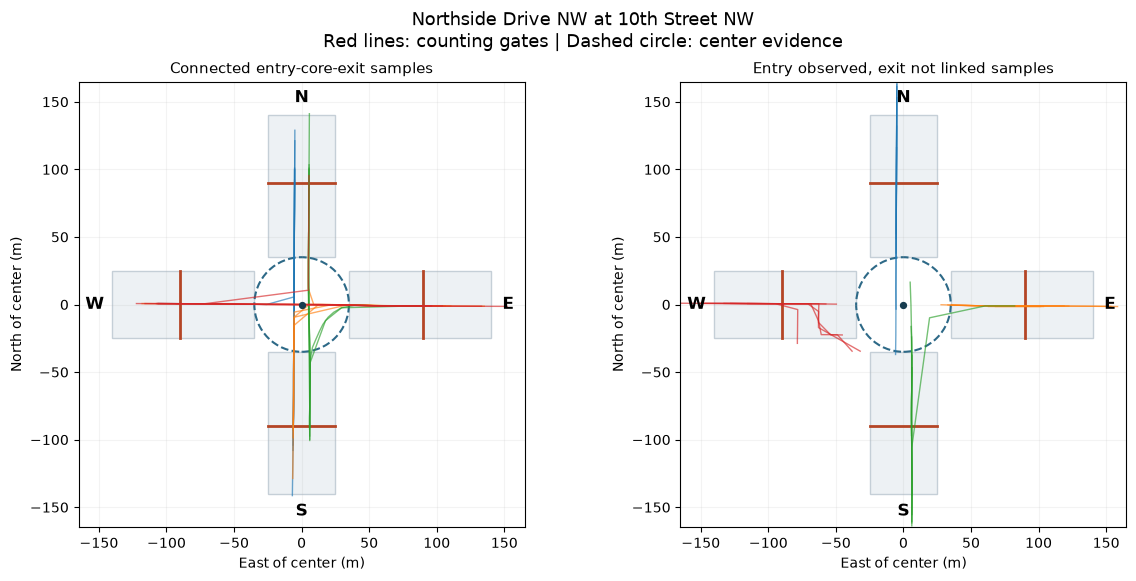

In [6]:
if 'passages' not in globals():
    raise RuntimeError('Run the setup and streaming aggregation cells above first.')
from matplotlib.patches import Circle

def draw_site(ax):
    w, length = CORRIDOR_HALF_WIDTH_M, ARM_EXTENT_M
    for arm in APPROACH_ORDER:
        u = ARM_UNIT[arm]
        v = np.array([-u[1], u[0]])
        poly = np.array([u*CORE_RADIUS_M-v*w, u*length-v*w,
                         u*length+v*w, u*CORE_RADIUS_M+v*w])
        ax.fill(poly[:, 0], poly[:, 1], color='#edf1f4', edgecolor='#c5cfd7', zorder=0)
        gate = np.array([u*GATE_DISTANCE_M-v*w, u*GATE_DISTANCE_M+v*w])
        ax.plot(gate[:, 0], gate[:, 1], color='#b44525', lw=2)
        label_xy = u * (length + 13)
        ax.text(*label_xy, arm, ha='center', va='center', weight='bold', fontsize=12)
    ax.add_patch(Circle((0, 0), CORE_RADIUS_M, fill=False, color='#2d6987', ls='--', lw=1.5))
    ax.scatter([0], [0], color='#183d50', s=18, zorder=5)
    ax.set(xlim=(-165, 165), ylim=(-165, 165), xlabel='East of center (m)', ylabel='North of center (m)')
    ax.set_aspect('equal');ax.grid(alpha=.15)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.7), constrained_layout=True)
for ax, connected in zip(axes, [True, False]):
    draw_site(ax)
    for arm in APPROACH_ORDER:
        for sample in site_scanner.examples.get((arm, connected), []):
            for segment in sample['segments']:
                ax.plot(segment[:, 0], segment[:, 1], lw=1, alpha=.65,
                        color=plt.get_cmap('tab10')(APPROACH_ORDER.index(arm)))
    ax.set_title('Connected entry-core-exit samples' if connected else 'Entry observed, exit not linked samples', fontsize=11)
fig.suptitle(SITE_NAME + chr(10) + 'Red lines: counting gates | Dashed circle: center evidence', fontsize=13)
plt.show()
# This is a diagnostic sample (up to six trip-approach records per group), not a frequency map.

## Approach Counts and Trajectory Connection

**Observed trips** crossed an inbound gate. **Connected trips** additionally satisfy the entry-center-exit rule. The connection rate is connected / observed on that approach; it measures usable trajectory coverage, not traffic or controller performance. The entry-to-exit matrix shows where the connected paths leave. Same-side exits are retained as U-turn candidates for review.

,observed_trips,connected_trips,observed_dates,unlinked_trips,connection_rate_pct
From north (southbound),1596,813,31,783,50.9
From east (westbound),746,128,31,618,17.2
From south (northbound),1571,630,31,941,40.1
From west (eastbound),619,61,31,558,9.9


Distinct trips with an entry: 4286
Distinct trips with a connected crossing: 1602
Trip-approach pairs: 4532
Trips counted on more than one approach: 239


,Check,Count
0,nearby trip rows,6174
1,nearby adjacent pairs,118258
2,nearby rejected pairs,12885
3,inbound gate events,4559
4,outbound gate events,4555
5,observed trip approach pairs,4532
6,connected trip approach pairs,1632
7,nearby trips without entry,1888


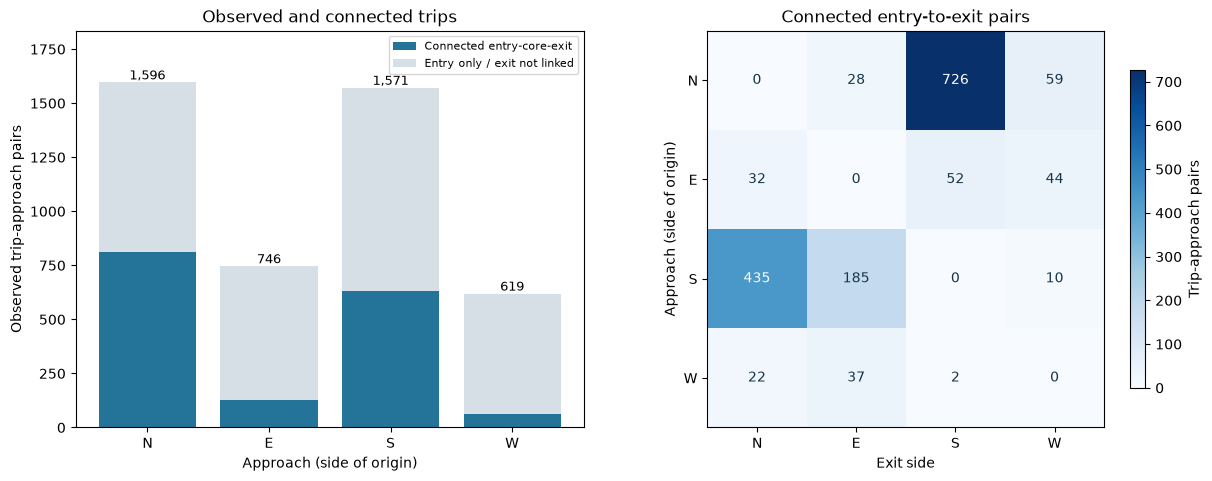

In [7]:
if passages.empty:
    raise ValueError('No qualifying inbound crossings. Inspect coordinates, thresholds, and trip coverage.')
site_summary = passages.groupby('approach').agg(
    observed_trips=('connected', 'size'), connected_trips=('connected', 'sum'),
    observed_dates=('local_date', 'nunique')).reindex(APPROACH_ORDER, fill_value=0)
site_summary['unlinked_trips'] = site_summary['observed_trips'] - site_summary['connected_trips']
site_summary['connection_rate_pct'] = (100 * site_summary['connected_trips'] /
                                        site_summary['observed_trips'].replace(0, np.nan))
site_summary.index = [APPROACH_LABELS[a] for a in APPROACH_ORDER]
display(site_summary.round(1))
print('Distinct trips with an entry:', passages['trip_key'].nunique())
print('Distinct trips with a connected crossing:', passages.loc[passages['connected'], 'trip_key'].nunique())
print('Trip-approach pairs:', len(passages))
print('Trips counted on more than one approach:', int((passages.groupby('trip_key').size() > 1).sum()))
display(pd.DataFrame([{'Check': k.replace('_', ' '), 'Count': v} for k,v in site_stats.items()]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), constrained_layout=True)
x = np.arange(4)
observed = site_summary['observed_trips'].to_numpy()
connected = site_summary['connected_trips'].to_numpy()
axes[0].bar(x, connected, color='#24749a', label='Connected entry-core-exit')
axes[0].bar(x, observed-connected, bottom=connected, color='#d6dfe6', label='Entry only / exit not linked')
for i, count in enumerate(observed):
    axes[0].text(i, count, f'{count:,}', ha='center', va='bottom', fontsize=9)
axes[0].set(xticks=x, xticklabels=APPROACH_ORDER, xlabel='Approach (side of origin)', ylabel='Observed trip-approach pairs', title='Observed and connected trips')
axes[0].margins(y=.15);axes[0].legend(fontsize=8)
exit_matrix = pd.crosstab(passages.loc[passages['connected'], 'approach'],
                         passages.loc[passages['connected'], 'exit_arm']).reindex(
                             index=APPROACH_ORDER, columns=APPROACH_ORDER, fill_value=0)
im = axes[1].imshow(exit_matrix, cmap='Blues')
for i in range(4):
    for j in range(4):
        value = int(exit_matrix.iloc[i,j])
        axes[1].text(j, i, f'{value:,}', ha='center', va='center',
                     color='white' if value > exit_matrix.to_numpy().max()*.55 else '#173548')
axes[1].set(xticks=x, xticklabels=APPROACH_ORDER, yticks=x, yticklabels=APPROACH_ORDER,
            xlabel='Exit side', ylabel='Approach (side of origin)', title='Connected entry-to-exit pairs')
fig.colorbar(im, ax=axes[1], shrink=.8, label='Trip-approach pairs')
plt.show()

## Dates and Times of Day

Assign each record to its **local gate-entry time**, not its trip-start time. The date-hour heatmap counts all observed entries; the approach panels show how those entries are distributed. A gray cell contains no qualifying observations and must not be interpreted as verified zero traffic.

The hourly curves are **mean counts per calendar day** in the extract, including days with no qualifying observations. Separate weekday/weekend denominators prevent their unequal number of dates from distorting the comparison. Solid curves show entries; dashed curves show connected records.

Finally compare 15-, 30-, and 60-minute windows. Report the fraction of windows with at least five records as a descriptive sample-size check; five is not a statistical adequacy threshold.

Entries outside the requested calendar dates: 0


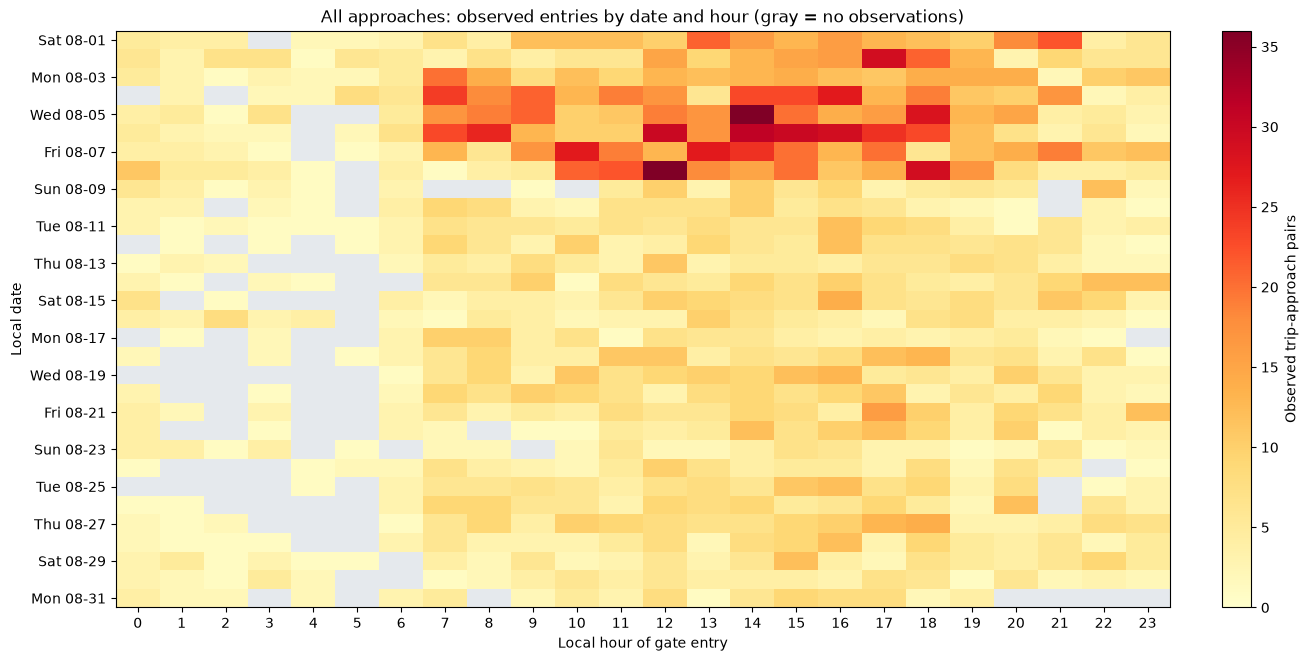

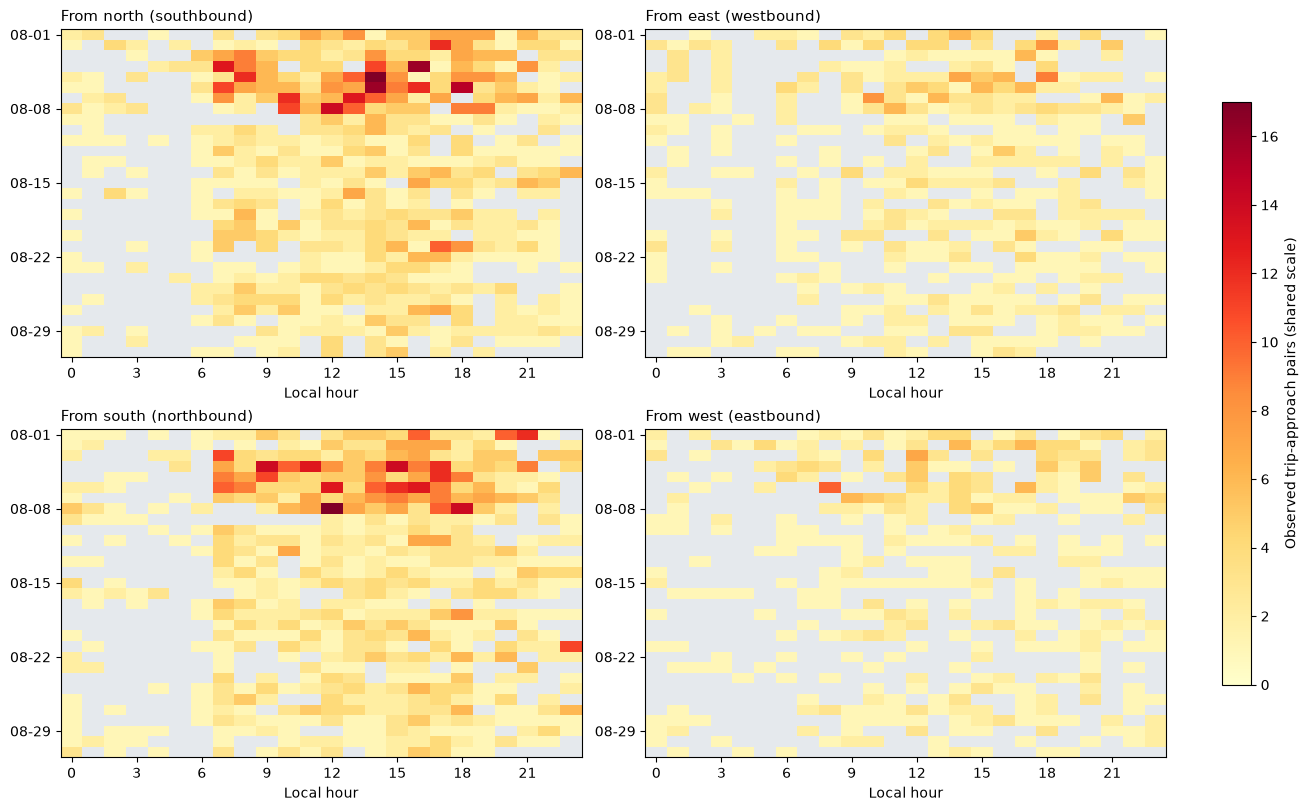

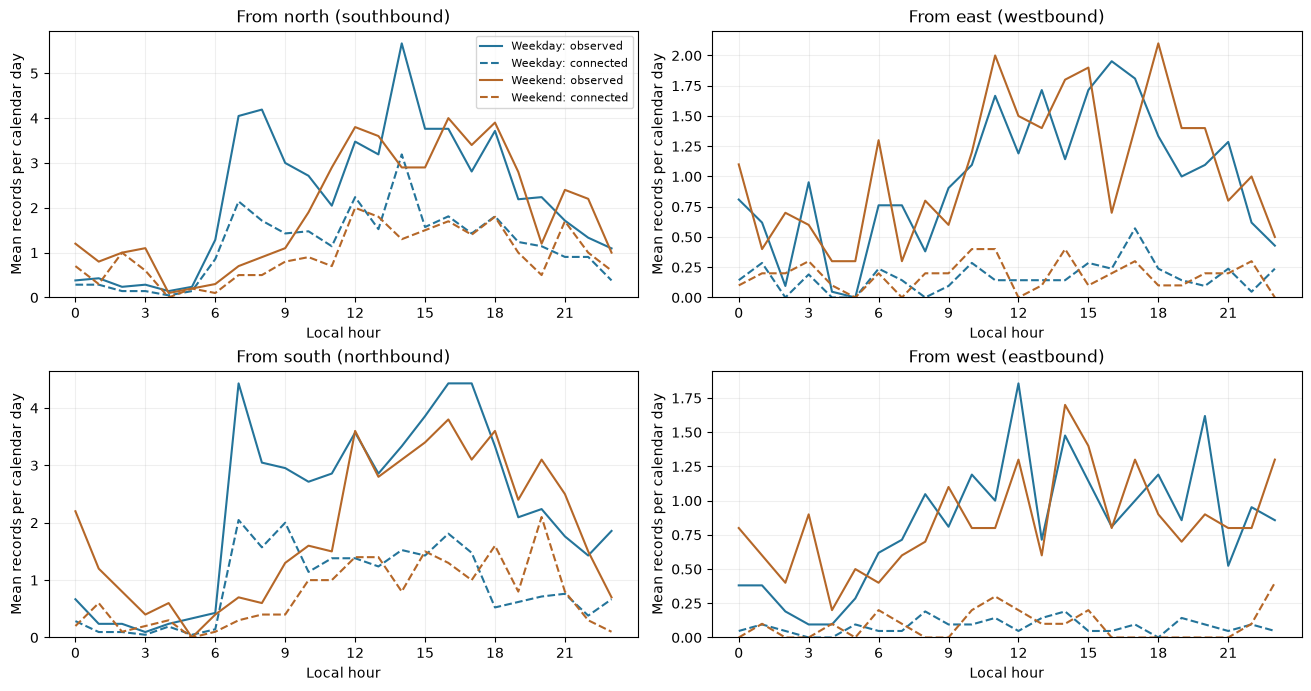

,minutes,approach,records,median_count_06_22,p10_count_06_22,p90_count_06_22,windows_with_any_pct_06_22,windows_with_5plus_pct_06_22
0,15,N,Observed,0.0,0.0,2.0,41.3,1.7
1,15,N,Connected,0.0,0.0,1.0,24.1,0.5
2,15,E,Observed,0.0,0.0,1.0,22.6,0.3
3,15,E,Connected,0.0,0.0,0.0,4.0,0.0
4,15,S,Observed,0.0,0.0,2.0,40.3,1.7
5,15,S,Connected,0.0,0.0,1.0,20.0,0.2
6,15,W,Observed,0.0,0.0,1.0,17.9,0.2
7,15,W,Connected,0.0,0.0,0.0,2.1,0.0
8,30,N,Observed,1.0,0.0,4.0,63.0,6.0
9,30,N,Connected,0.0,0.0,2.0,40.9,1.8


Window checks use 06:00–22:00 local time and include all extraction dates.


In [8]:
extract_start = pd.Timestamp(MANIFEST['request']['from_date']).normalize()
extract_end = pd.Timestamp(MANIFEST['request']['to_date']).normalize()
calendar_dates = pd.date_range(extract_start, extract_end, freq='D')
inside_dates = passages['local_date'].between(extract_start, extract_end)
print('Entries outside the requested calendar dates:', int((~inside_dates).sum()))
site_events = passages.loc[inside_dates].copy()
if site_events.empty:
    raise ValueError('No site entries within the extraction calendar.')
all_hours = np.arange(24)

def date_hour_counts(frame):
    return (frame.groupby(['local_date', 'hour']).size().unstack('hour', fill_value=0)
            .reindex(index=calendar_dates, columns=all_hours, fill_value=0))

heat_all = date_hour_counts(site_events)
cmap = plt.get_cmap('YlOrRd').copy();cmap.set_bad('#e5e9ed')
fig, ax = plt.subplots(figsize=(13, 6.5), constrained_layout=True)
vmax = max(1, int(heat_all.to_numpy().max()))
im = ax.imshow(np.ma.masked_equal(heat_all.to_numpy(), 0), aspect='auto', cmap=cmap, vmin=0, vmax=vmax)
ax.set(xticks=all_hours, xlabel='Local hour of gate entry', ylabel='Local date',
       title='All approaches: observed entries by date and hour (gray = no observations)')
ax.set_yticks(np.arange(len(calendar_dates))[::2], [d.strftime('%a %m-%d') for d in calendar_dates[::2]])
fig.colorbar(im, ax=ax, label='Observed trip-approach pairs')
plt.show()

approach_heat = {a: date_hour_counts(site_events[site_events['approach']==a]) for a in APPROACH_ORDER}
shared_max = max(1, max(int(h.to_numpy().max()) for h in approach_heat.values()))
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for ax, arm in zip(axes.flat, APPROACH_ORDER):
    im = ax.imshow(np.ma.masked_equal(approach_heat[arm].to_numpy(), 0), aspect='auto',
                   cmap=cmap, vmin=0, vmax=shared_max)
    ax.set_title(APPROACH_LABELS[arm], loc='left', fontsize=11)
    ax.set(xticks=np.arange(0,24,3), xlabel='Local hour')
    ax.set_yticks(np.arange(len(calendar_dates))[::7], [d.strftime('%m-%d') for d in calendar_dates[::7]])
fig.colorbar(im, ax=axes, shrink=.8, label='Observed trip-approach pairs (shared scale)')
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 6.8), constrained_layout=True)
for ax, arm in zip(axes.flat, APPROACH_ORDER):
    for day_type, color in [('Weekday','#24749a'), ('Weekend','#b56728')]:
        mask = calendar_dates.day_of_week < 5 if day_type=='Weekday' else calendar_dates.day_of_week >= 5
        n_days = int(mask.sum())
        subset = site_events[(site_events['approach']==arm) & (site_events['day_type']==day_type)]
        for connected_only, linestyle in [(False,'-'), (True,'--')]:
            frame = subset[subset['connected']] if connected_only else subset
            y = frame.groupby('hour').size().reindex(all_hours, fill_value=0) / n_days
            ax.plot(all_hours, y, color=color, ls=linestyle,
                    label=f'{day_type}: '+('connected' if connected_only else 'observed'))
    ax.set(title=APPROACH_LABELS[arm], xlabel='Local hour', ylabel='Mean records per calendar day', xticks=np.arange(0,24,3))
    ax.set_ylim(bottom=0);ax.grid(alpha=.2)
axes.flat[0].legend(fontsize=8)
plt.show()

window_checks = []
for minutes in [15,30,60]:
    windows = pd.date_range(extract_start, extract_end + pd.Timedelta(days=1), freq=f'{minutes}min', inclusive='left')
    binned = site_events['entry_time'].dt.floor(f'{minutes}min')
    for arm in APPROACH_ORDER:
        for kind in ['Observed','Connected']:
            select = site_events['approach'].eq(arm)
            if kind=='Connected':select &= site_events['connected']
            counts = binned[select].value_counts().reindex(windows, fill_value=0)
            daytime = (windows.hour>=6) & (windows.hour<22)
            active = counts.iloc[np.flatnonzero(daytime)]
            window_checks.append({'minutes':minutes,'approach':arm,'records':kind,
                                  'median_count_06_22':float(active.median()),
                                  'p10_count_06_22':float(active.quantile(.1)),
                                  'p90_count_06_22':float(active.quantile(.9)),
                                  'windows_with_any_pct_06_22':100*float((active>0).mean()),
                                  'windows_with_5plus_pct_06_22':100*float((active>=5).mean())})
window_coverage = pd.DataFrame(window_checks)
display(window_coverage.round(1))
print('Window checks use 06:00–22:00 local time and include all extraction dates.')

## Reading the Site Results

Start with the least-observed approach, not the intersection total. Check whether its connected paths appear repeatedly across dates and daytime hours. Compare aggregation windows before choosing a time resolution for demand or turning EDA.

Use the sample paths and gate diagram to review the geometry and detection rules. Connection rates depend on sampling gaps, missing positions, thresholds, and driveway/parking movements; they are not a validation score. A small or absent movement count may reflect limited observations. This analysis has not estimated the Compass penetration rate or verified signal phases.